# SHL Labs 2026 — Audio Grammar Scoring Engine

**Kaggle GPU notebook | Transcript + acoustic features + ensemble regression**

This notebook ingests the competition audio, extracts Whisper transcripts and audio features, evaluates regression models using **5-fold out-of-fold (OOF) RMSE, MAE and Pearson correlation**, reports the **compulsory training RMSE**, and produces an audited submission.

**Integrity warning:** The CSVs supplied with the request have 769 train rows, 216 test rows, and 204 template rows; 212 train and test filenames overlap. The notebook *does not* assume identical filenames imply identical recordings. It resolves train/test audio separately and checks content hashes before model fitting. If actual train/test recordings share content, execution stops instead of exploiting leakage.

**Setup:** Kaggle → New Notebook → Accelerator GPU (T4/P100) → Add Input → attach the SHL competition data. Enable Internet if packages/model weights are not cached. Expected output: `/kaggle/working/submission.csv`. No numerical validation claims are made until the notebook runs.

In [2]:
# Install extra dependencies in Kaggle (requires internet the first time).
%pip -q install -U faster-whisper catboost language-tool-python==2.9.4

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 55.5/55.5 kB 990.5 kB/s eta 0:00:00 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 55.6/55.6 kB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 6.5 MB/s eta 0:00:0000:01:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.0/35.0 MB 4.3 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 39.6/39.6 MB 3.7 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.6/23.6 MB 2.5 MB/s eta 0:00:0000:0100:01
Note: you may need to restart the kernel to use updated packages.


In [3]:
import os, re, json, hashlib, warnings, gc, time
from pathlib import Path
from collections import Counter
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from tqdm.auto import tqdm
from scipy.stats import pearsonr
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.impute import SimpleImputer
from sklearn.ensemble import ExtraTreesRegressor, HistGradientBoostingRegressor
from catboost import CatBoostRegressor
import librosa
import torch
warnings.filterwarnings('ignore', category=FutureWarning)
SEED=42; np.random.seed(SEED)
WORK=Path('/kaggle/working') if Path('/kaggle').exists() else Path.cwd()
CACHE=WORK/'shl_cache'; CACHE.mkdir(parents=True, exist_ok=True)
print('GPU:',torch.cuda.is_available(), 'Working:',WORK)

GPU: True Working: /kaggle/working


## 1. Locate files and validate the manifest

The official competition's exact mounted directory can vary. We prefer CSV files under a `Dataset_Final` directory when present, and resolve recordings separately under train/test audio trees. **Do not use the sample-submission filenames as test identifiers** unless they exactly match the test manifest.

In [4]:
INPUT_ROOT=Path('/kaggle/input') if Path('/kaggle/input').exists() else Path('/mnt/data')
TRAIN_CSV_OVERRIDE=None  # e.g. '/kaggle/input/.../Dataset_Final/train.csv'
TEST_CSV_OVERRIDE=None
SAMPLE_CSV_OVERRIDE=None

def choose_csv(name, override=None):
    if override: return Path(override)
    candidates=list(INPUT_ROOT.rglob(name))
    candidates=sorted(candidates,key=lambda x:(0 if 'Dataset_Final' in str(x) else 1,len(str(x))))
    if not candidates: raise FileNotFoundError(f'{name} not found under {INPUT_ROOT}. Attach Kaggle dataset.')
    print(f'{name}: {candidates[0]}  ({len(candidates)} candidate(s))')
    return candidates[0]
train_path=choose_csv('train.csv',TRAIN_CSV_OVERRIDE)
test_path=choose_csv('test.csv',TEST_CSV_OVERRIDE)
sample_candidates=list(INPUT_ROOT.rglob('sample_submission.csv'))
sample_path=choose_csv('sample_submission.csv',SAMPLE_CSV_OVERRIDE) if sample_candidates or SAMPLE_CSV_OVERRIDE else None
train=pd.read_csv(train_path); test=pd.read_csv(test_path)
sample=pd.read_csv(sample_path) if sample_path else None
for name,df in [('train',train),('test',test)]:
    assert {'filename','label'}.issubset(df.columns),f'{name}: missing expected columns'
    assert df.filename.notna().all() and df.filename.is_unique,f'{name}: null/duplicate identifiers'
    df['filename']=df.filename.astype(str).str.strip()
train['label']=pd.to_numeric(train['label'],errors='raise')
assert train.label.notna().all() and train.label.between(0,5).all(),'Invalid training labels'
print('Rows:',len(train),len(test),'sample:',len(sample) if sample is not None else 'absent')
print('Train score summary:\n',train.label.describe())
name_overlap=set(train.filename)&set(test.filename)
print('Train/test filename overlap:',len(name_overlap))
if sample is not None:
    print('Template/test exact match?',set(sample.filename)==set(test.filename),
          '| template/test shared:',len(set(sample.filename)&set(test.filename)))
    if set(sample.filename)!=set(test.filename):
        print('WARNING: sample template does not match test.csv. Will generate test.csv-aligned submission.')
assert test.filename.is_unique

train.csv: /kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/train.csv  (1 candidate(s))
test.csv: /kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/test.csv  (1 candidate(s))
sample_submission.csv: /kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/sample_submission.csv  (1 candidate(s))
Rows: 769 216 sample: 204
Train score summary:
 count    769.000000
mean       3.313394
std        1.239000
min        0.000000
25%        2.500000
50%        3.000000
75%        4.000000
max        5.000000
Name: label, dtype: float64
Train/test filename overlap: 212
Template/test exact match? False | template/test shared: 25


In [5]:
# Directory-aware audio lookup. Do not silently resolve train audio to test audio.
AUDIO_EXT={'.wav','.mp3','.flac','.m4a','.ogg'}
all_audio=[p for p in INPUT_ROOT.rglob('*') if p.is_file() and p.suffix.lower() in AUDIO_EXT]
print('Audio files found:',len(all_audio))

def rank_path(p, split, csv_dir):
    parts=[s.lower() for s in p.parts]
    rel=str(p).lower()
    score=0
    if split in parts: score+=100
    if f'/{split}/' in rel or f'\\{split}\\' in rel: score+=100
    if 'audios' in parts or 'audio' in parts: score+=15
    if p.parent==csv_dir: score+=5
    if ('test' if split=='train' else 'train') in parts: score-=300
    return score

def resolve(df,split,csvpath):
    by_name={}
    for p in all_audio: by_name.setdefault(p.name.lower(),[]).append(p)
    paths=[]; ambiguous=[]; missing=[]
    for filename in df.filename:
        candidates=by_name.get(Path(filename).name.lower(),[])
        if not candidates: missing.append(filename);paths.append(None);continue
        ranked=sorted(candidates,key=lambda p:rank_path(p,split,csvpath.parent),reverse=True)
        best=rank_path(ranked[0],split,csvpath.parent)
        ties=[p for p in ranked if rank_path(p,split,csvpath.parent)==best]
        if len(ties)>1: ambiguous.append((filename,[str(t) for t in ties[:4]]))
        paths.append(ranked[0])
    if missing or ambiguous:
        print(f'{split} missing (first 8):',missing[:8]);print(f'{split} ambiguous (first 4):',ambiguous[:4])
        raise RuntimeError('Cannot uniquely resolve audio files. Set correct dataset/split paths before training.')
    return paths
assert all_audio,'No audio. Attach Dataset_Final in Kaggle Add Input.'
train_paths=resolve(train,'train',train_path);test_paths=resolve(test,'test',test_path)
print('Example train:',train_paths[0]);print('Example test:',test_paths[0])

Audio files found: 985
Example train: /kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/train/audio_192.wav
Example test: /kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/test/audio_128.wav


### Audio-content leakage audit

If a filename exists in both CSVs, that alone is not proof of leakage: independent `train/` and `test/` directories could contain different bytes. We hash **every file** to detect identical audio. The notebook fails closed on hash overlap, duplicate test content, or resolving a train and test row to the same physical file. Do not use public or hidden test labels as training targets.

In [6]:
def sha256(path):
    h=hashlib.sha256()
    with open(path,'rb') as f:
        for chunk in iter(lambda:f.read(1024*1024),b''): h.update(chunk)
    return h.hexdigest()
train_hashes=[sha256(p) for p in tqdm(train_paths,desc='Hashing train')]
test_hashes=[sha256(p) for p in tqdm(test_paths,desc='Hashing test')]
shared_hashes=set(train_hashes)&set(test_hashes)
shared_paths=set(map(lambda p:str(p.resolve()),train_paths))&set(map(lambda p:str(p.resolve()),test_paths))
print('Train/test same-content hashes:',len(shared_hashes),'same physical paths:',len(shared_paths))
print('Within-train duplicate audio hashes:',len(train_hashes)-len(set(train_hashes)))
print('Within-test duplicate audio hashes:',len(test_hashes)-len(set(test_hashes)))
assert not shared_hashes and not shared_paths, ('TRAIN/TEST AUDIO LEAKAGE DETECTED. '
     'Check that matching filenames map to distinct audio and verify the correct dataset manifests.')
assert len(set(test_hashes))==len(test_hashes),'Duplicate recordings in test manifest; review source data.'

Hashing train:   0%|          | 0/769 [00:00<?, ?it/s]

Hashing test:   0%|          | 0/216 [00:00<?, ?it/s]

Train/test same-content hashes: 0 same physical paths: 0
Within-train duplicate audio hashes: 0
Within-test duplicate audio hashes: 0


## 2. Exploratory analysis

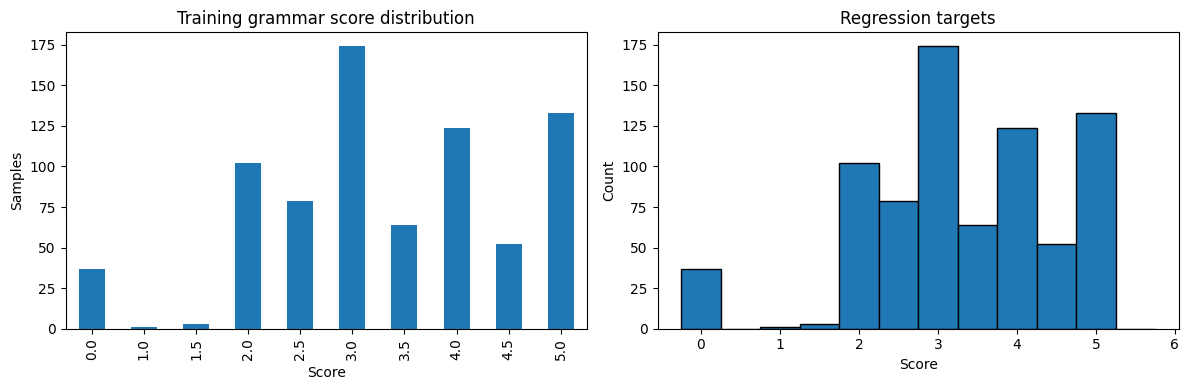

In [7]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
train.label.value_counts().sort_index().plot.bar(ax=axes[0],title='Training grammar score distribution')
axes[0].set(xlabel='Score',ylabel='Samples')
axes[1].hist(train.label,bins=np.arange(-.25,5.76,.5),edgecolor='black')
axes[1].set(xlabel='Score',ylabel='Count',title='Regression targets')
plt.tight_layout();plt.show()

## 3. Audio features + Whisper transcription

`faster-whisper` runs on Kaggle GPU. Outputs are cached to disk by content digest so reruns can reuse them. Linguistic heuristics are imperfect because ASR can normalize spoken grammar. Audio features are supporting features, not replacements for grammar analysis.

In [8]:
from faster_whisper import WhisperModel
WHISPER_SIZE='small' # increase to 'medium' if GPU memory / runtime permits
DEVICE='cuda' if torch.cuda.is_available() else 'cpu'
COMPUTE='float16' if DEVICE=='cuda' else 'int8'
whisper=WhisperModel(WHISPER_SIZE,device=DEVICE,compute_type=COMPUTE)
print('Transcriber:',WHISPER_SIZE,DEVICE)

Transcriber: small cuda


In [12]:
def audio_features(path):
    y,sr=librosa.load(str(path),sr=16000,mono=True)
    if len(y)<sr: raise ValueError(f'Audio too short: {path}')
    hop=512
    feat={'duration_s':len(y)/sr,'peak_amp':float(np.max(np.abs(y))),
          'silence_ratio':float(np.mean(librosa.feature.rms(y=y,hop_length=hop)[0]<0.01))}
    measures={
        'rms':librosa.feature.rms(y=y,hop_length=hop)[0],
        'zcr':librosa.feature.zero_crossing_rate(y,hop_length=hop)[0],
        'centroid':librosa.feature.spectral_centroid(y=y,sr=sr,hop_length=hop)[0],
        'bandwidth':librosa.feature.spectral_bandwidth(y=y,sr=sr,hop_length=hop)[0],
        'rolloff':librosa.feature.spectral_rolloff(y=y,sr=sr,hop_length=hop)[0],
    }
    mfcc=librosa.feature.mfcc(y=y,sr=sr,n_mfcc=13,hop_length=hop)
    for j in range(13): measures[f'mfcc_{j+1}']=mfcc[j]
    for name,arr in measures.items():
        feat[name+'_mean']=float(np.nanmean(arr))
        feat[name+'_std']=float(np.nanstd(arr))
    return feat

def transcribe(path):
    # Decode and resample audio with Librosa instead of PyAV
    audio, sr = librosa.load(
        str(path),
        sr=16000,
        mono=True
    )

    segments, meta = whisper.transcribe(
        audio,
        beam_size=3,
        language="en",
        vad_filter=True,
        condition_on_previous_text=False
    )

    segs = list(segments)

    return {
        "transcript": " ".join(
            s.text.strip() for s in segs
        ),
        "asr_segment_count": len(segs),
        "asr_speech_seconds": float(
            sum(max(0, s.end - s.start) for s in segs)
        )
    }

def extract_one(path,content_hash):
    cache_path=CACHE/(content_hash+'_'+WHISPER_SIZE+'.json')
    if cache_path.exists(): return json.loads(cache_path.read_text())
    out={**audio_features(path),**transcribe(path)}
    cache_path.write_text(json.dumps(out))
    return out

all_paths=train_paths+test_paths;all_hashes=train_hashes+test_hashes
rows=[]
for path,digest in tqdm(zip(all_paths,all_hashes),total=len(all_paths),desc='Features + ASR'):
    rows.append(extract_one(path,digest))
base=pd.DataFrame(rows)
base.to_csv(WORK/'asr_audio_features.csv',index=False)
print('Transcripts cached; sample (first 250 characters):',base.transcript.iloc[0][:250])

Features + ASR:   0%|          | 0/985 [00:00<?, ?it/s]

Transcripts cached; sample (first 250 characters): The playground is very, very beautiful and fun. There are places like the merry-go-round, the swing. The students usually enjoy the swing. It has to be like, it's more like a game of play, because once it's in it and the other person will have to pus


## 4. Grammar and linguistic features

LanguageTool features capture surface grammar suggestions and error categories; lexical and structural proxies capture sentence variety, repeated words and pauses. LanguageTool may need a Java runtime. If unavailable, its features are excluded consistently for all rows (instead of substituting fake zero errors).

In [10]:
import language_tool_python
try:
    grammar_tool=language_tool_python.LanguageTool('en-US')
    print('LanguageTool enabled')
except Exception as exc:
    grammar_tool=None
    print('LanguageTool unavailable:',str(exc)[:180], '\nProceeding with lexical features.')

def text_features(text):
    text=str(text or '')
    words=re.findall(r"[A-Za-z]+(?:'[A-Za-z]+)?",text.lower())
    sentences=[s.strip() for s in re.split(r'[.!?]+',text) if s.strip()]
    n=len(words)
    count=Counter(words)
    fillers=sum(count[w] for w in ('um','uh','erm','like','actually','basically'))
    repeated=sum(words[i]==words[i-1] for i in range(1,n))
    return dict(word_count=n,unique_ratio=len(count)/max(1,n),
                sentence_count=len(sentences),words_per_sentence=n/max(1,len(sentences)),
                avg_word_len=np.mean(list(map(len,words))) if words else 0,
                long_word_ratio=sum(len(w)>=7 for w in words)/max(1,n),
                filler_ratio=fillers/max(1,n),repeat_ratio=repeated/max(1,n),
                question_count=text.count('?'),
                conjunction_ratio=sum(count[w] for w in ('because','although','however','while','unless','whereas','since'))/max(1,n))

def grammar_features(text):
    if grammar_tool is None: return {}
    try:
        matches=grammar_tool.check(str(text or ''))
        cat=Counter(str(getattr(m,'rule_issue_type','unknown')).lower() for m in matches)
        n=max(1,len(re.findall(r'\b\w+\b',str(text))))
        return {'grammar_errors':len(matches),'grammar_errors_per_100_words':100*len(matches)/n,
                'grammar_grammar_count':cat.get('grammar',0),
                'grammar_misspelling_count':cat.get('misspelling',0)}
    except Exception: return {'grammar_errors':np.nan,'grammar_errors_per_100_words':np.nan,
                              'grammar_grammar_count':np.nan,'grammar_misspelling_count':np.nan}

linguistic=[]
for transcript in tqdm(base.transcript.fillna(''),desc='Grammar features'):
    linguistic.append({**text_features(transcript),**grammar_features(transcript)})
ling_df=pd.DataFrame(linguistic)
features=pd.concat([base.drop(columns=['transcript']).reset_index(drop=True),ling_df],axis=1)
feature_cols=list(features.select_dtypes(include=np.number).columns)
X_train=features.iloc[:len(train)][feature_cols].reset_index(drop=True)
X_test=features.iloc[len(train):][feature_cols].reset_index(drop=True)
y=train.label.to_numpy(dtype=float)
print('Features:',len(feature_cols),'X train:',X_train.shape,'X test:',X_test.shape)
features.to_csv(WORK/'engineered_features.csv',index=False)

Unzipping /tmp/tmpgp0mdjzr.zip to /root/.cache/language_tool_python.
Downloaded https://internal1.languagetool.org/snapshots/LanguageTool-latest-snapshot.zip to /root/.cache/language_tool_python.


LanguageTool enabled


Grammar features:   0%|          | 0/985 [00:00<?, ?it/s]

Features: 55 X train: (769, 55) X test: (216, 55)


## 5. Leakage-safe model comparison and evaluation

5-fold grouped CV is used **if duplicate audio hashes occur within train**, otherwise shuffled 5-fold KFold. All imputation is trained inside each fold. We compare a regularized-ish ExtraTrees model and CatBoost. Test predictions are averaged across CV models. OOF predictions are never used as training targets. The training RMSE is calculated separately after fitting a final model to the full training dataset; it is **optimistic** and not a generalization metric.

In [13]:
from sklearn.model_selection import GroupKFold
from sklearn.base import clone

def metrics(actual,pred):
    pred=np.clip(np.asarray(pred,float),0,5)
    corr=float(pearsonr(actual,pred).statistic) if np.std(pred)>0 and np.std(actual)>0 else np.nan
    return {'RMSE':float(np.sqrt(mean_squared_error(actual,pred))),
            'MAE':float(mean_absolute_error(actual,pred)), 'Pearson':corr}

models={
    'CatBoost':CatBoostRegressor(iterations=950,depth=5,learning_rate=.035,l2_leaf_reg=6,
                                loss_function='RMSE',random_seed=SEED,verbose=False,thread_count=4),
    'ExtraTrees':ExtraTreesRegressor(n_estimators=500,max_features=.85,min_samples_leaf=3,
                                     random_state=SEED,n_jobs=-1),
}
if len(set(train_hashes))<len(train_hashes):
    splits=list(GroupKFold(n_splits=5).split(X_train,y,groups=train_hashes))
    print('Using grouped folds to prevent same-content validation leakage')
else:
    splits=list(KFold(n_splits=5,shuffle=True,random_state=SEED).split(X_train,y))

oof={};test_preds={};summary=[]
for model_name,model in models.items():
    predictions=np.zeros(len(train));test_fold=[]
    for k,(tr,va) in enumerate(splits,1):
        imputer=SimpleImputer(strategy='median',add_indicator=False)
        a=imputer.fit_transform(X_train.iloc[tr]);b=imputer.transform(X_train.iloc[va]);c=imputer.transform(X_test)
        fitted=clone(model);fitted.fit(a,y[tr])
        predictions[va]=np.clip(fitted.predict(b),0,5)
        test_fold.append(np.clip(fitted.predict(c),0,5))
        print(model_name,'fold',k,'RMSE',round(metrics(y[va],predictions[va])['RMSE'],4))
    oof[model_name]=predictions;test_preds[model_name]=np.mean(test_fold,axis=0)
    res={'Model':model_name,**metrics(y,predictions)};summary.append(res)
results=pd.DataFrame(summary).sort_values('RMSE')
display(results)

CatBoost fold 1 RMSE 0.6455
CatBoost fold 2 RMSE 0.6974
CatBoost fold 3 RMSE 0.7568
CatBoost fold 4 RMSE 0.6954
CatBoost fold 5 RMSE 0.7234
ExtraTrees fold 1 RMSE 0.6592
ExtraTrees fold 2 RMSE 0.7389
ExtraTrees fold 3 RMSE 0.8001
ExtraTrees fold 4 RMSE 0.6994
ExtraTrees fold 5 RMSE 0.7602


,Model,RMSE,MAE,Pearson
0,CatBoost,0.704620,0.548380,0.822992
1,ExtraTrees,0.733118,0.583814,0.809333


In [15]:
# Optional simple blend: keep only if it improves OOF RMSE.
primary=results.iloc[0]['Model']
selected_oof=oof[primary].copy();selected_test=test_preds[primary].copy();selected_name=primary
if len(models)>1:
    names=list(models)
    blend_oof=(oof[names[0]]+oof[names[1]])/2
    blend_test=(test_preds[names[0]]+test_preds[names[1]])/2
    if metrics(y,blend_oof)['RMSE']<metrics(y,selected_oof)['RMSE']:
        selected_name='Equal-weight blend';selected_oof=blend_oof;selected_test=blend_test
print('Selected:',selected_name, 'OOF metrics:',metrics(y,selected_oof))

Selected: CatBoost OOF metrics: {'RMSE': 0.7046196415964285, 'MAE': 0.5483795782799922, 'Pearson': 0.8229915143987427}


## 6. Compulsory training RMSE and diagnostics

The **training RMSE** below is computed using an in-sample fit on all 769 labeled rows (or the actual attached training count). The **OOF RMSE** is the appropriate evaluation estimate. A gap between them suggests overfitting.

COMPULSORY TRAINING RMSE: 0.208816
Training MAE/Pearson: 0.15972647532443604 0.9880291113638527
OOF VALIDATION RMSE: 0.704620
OOF VALIDATION Pearson: 0.822992
OOF VALIDATION MAE: 0.548380


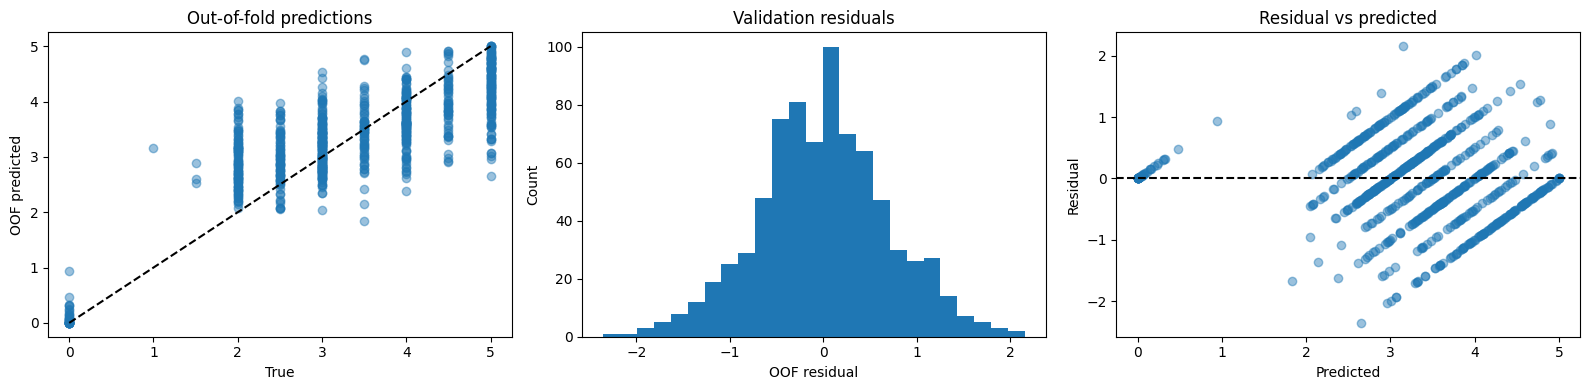

In [16]:
full_imp=SimpleImputer(strategy='median')
full_X=full_imp.fit_transform(X_train)
full_models={}
for model_name,model in models.items():
    fitted=clone(model);fitted.fit(full_X,y)
    full_models[model_name]=fitted
if selected_name=='Equal-weight blend':
    train_pred=np.mean([np.clip(m.predict(full_X),0,5) for m in full_models.values()],axis=0)
else:
    train_pred=np.clip(full_models[selected_name].predict(full_X),0,5)
train_scores=metrics(y,train_pred);oof_scores=metrics(y,selected_oof)
print('COMPULSORY TRAINING RMSE:',f"{train_scores['RMSE']:.6f}")
print('Training MAE/Pearson:',train_scores['MAE'],train_scores['Pearson'])
print('OOF VALIDATION RMSE:',f"{oof_scores['RMSE']:.6f}")
print('OOF VALIDATION Pearson:',f"{oof_scores['Pearson']:.6f}")
print('OOF VALIDATION MAE:',f"{oof_scores['MAE']:.6f}")
fig,axes=plt.subplots(1,3,figsize=(16,4))
axes[0].scatter(y,selected_oof,alpha=.45);axes[0].plot([0,5],[0,5],'k--');axes[0].set(xlabel='True',ylabel='OOF predicted',title='Out-of-fold predictions')
axes[1].hist(selected_oof-y,bins=25);axes[1].set(xlabel='OOF residual',ylabel='Count',title='Validation residuals')
axes[2].scatter(selected_oof,selected_oof-y,alpha=.45);axes[2].axhline(0,color='black',ls='--');axes[2].set(xlabel='Predicted',ylabel='Residual',title='Residual vs predicted')
plt.tight_layout();plt.show()
pd.DataFrame({'filename':train.filename,'actual':y,'oof_pred':selected_oof,'in_sample_pred':train_pred}).to_csv(WORK/'validation_diagnostics.csv',index=False)

## 7. Submission export with strict identifier audit

The provided sample template and test manifest may disagree. A submission must match **the competition's actual required IDs**. Here we export one prediction per `test.csv` row, in its exact order, using expected `filename,label` columns. We report the mismatch and refuse to claim this is guaranteed to match the current Kaggle submission schema until you confirm on Kaggle's Submissions page.

In [17]:
submission=test[['filename']].copy()
submission['label']=np.clip(selected_test,0,5)
assert len(submission)==len(test)
assert submission.filename.equals(test.filename)
assert submission.label.notna().all() and submission.label.between(0,5).all()
assert submission.filename.is_unique
if sample is not None:
    print('Template columns:',sample.columns.tolist(),'output columns:',submission.columns.tolist())
    if set(sample.filename)!=set(test.filename):
        print('NOTICE: Incompatible sample template; not using template identifiers.')
    if list(sample.columns)!=list(submission.columns):
        raise RuntimeError('Column mismatch with Kaggle sample submission: inspect official competition requirements.')
output=WORK/'submission.csv'
submission.to_csv(output,index=False)
print('Submission saved:',output,'rows:',len(submission))
display(submission.head())

Template columns: ['filename', 'label'] output columns: ['filename', 'label']
NOTICE: Incompatible sample template; not using template identifiers.
Submission saved: /kaggle/working/submission.csv rows: 216


,filename,label
0,audio_128.wav,2.421433
1,audio_156.wav,4.014254
2,audio_19.wav,3.691390
3,audio_108.wav,2.380397
4,audio_206.wav,2.942234


## 8. Auto-generated technical report

**Task:** Predict mean opinion score (MOS) for spoken grammar (range 0–5) from 45–60 second recordings.

**Preprocessing:** Audio is decoded to 16 kHz mono for acoustic statistics; Whisper speech-to-text uses English decoding and VAD. Dataset audio paths and SHA-256 hashes are audited. Transcript grammar indicators and lexical complexity features are combined with audio statistics. Features are cached for reproducibility.

**Architecture:** `Audio → Whisper ASR → linguistic/grammar features + acoustic features → fold-specific median imputation → CatBoost/ExtraTrees regressors → OOF evaluation → selected regression prediction → clamp to [0,5]`.

**Evaluation:** Five-fold cross-validation, minimizing RMSE, with Pearson and MAE reported. Model selection is performed using the same OOF folds; this model-selection step can impart some optimism. The separate compulsory training RMSE is in-sample and must not be confused with validation performance.

**Limitations:** Transcriptions may erase grammar errors; LanguageTool suggestions are not a perfect proxy for spontaneous spoken grammar; dataset size is small. Verify competition data splits, file hashes, exact submission IDs and evaluation terms before uploading. A hidden test score cannot be determined from the notebook alone.

In [18]:
report={
  'task':'SHL spoken grammar score regression 0-5',
  'train_rows':len(train),'test_rows':len(test),'features':feature_cols,
  'train_test_filename_overlap':len(name_overlap),
  'train_test_audio_hash_overlap':len(shared_hashes),
  'template_test_id_match':None if sample is None else set(sample.filename)==set(test.filename),
  'chosen_model':selected_name,
  'training_metrics_in_sample':train_scores,
  'validation_metrics_oof':oof_scores,
  'all_oof_models':results.to_dict('records'),
  'submission_path':str(output),
}
(WORK/'evaluation_report.json').write_text(json.dumps(report,indent=2))
print(json.dumps({k:report[k] for k in ['chosen_model','training_metrics_in_sample','validation_metrics_oof','submission_path']},indent=2))

{
  "chosen_model": "CatBoost",
  "training_metrics_in_sample": {
    "RMSE": 0.20881612071930916,
    "MAE": 0.15972647532443604,
    "Pearson": 0.9880291113638527
  },
  "validation_metrics_oof": {
    "RMSE": 0.7046196415964285,
    "MAE": 0.5483795782799922,
    "Pearson": 0.8229915143987427
  },
  "submission_path": "/kaggle/working/submission.csv"
}


In [19]:
import pandas as pd
import numpy as np
from pathlib import Path

work = Path("/kaggle/working")
submission_file = work / "submission.csv"

# Check submission file
assert submission_file.exists(), "Submission file is missing!"

submission = pd.read_csv(submission_file)

print("===== SHL FINAL VERIFICATION =====")
print("Submission shape:", submission.shape)
print("Columns:", submission.columns.tolist())

assert list(submission.columns) == ["filename", "label"]
assert len(submission) == 216, "Expected 216 predictions"
assert submission["filename"].is_unique
assert submission["filename"].notna().all()
assert submission["label"].notna().all()
assert np.isfinite(submission["label"]).all()
assert submission["label"].between(0, 5).all()

# Check alignment with the official test CSV
test_file = (
    Path("/kaggle/input/competitions/"
         "shl-hiring-assessment-2026/"
         "Dataset_Final/test.csv")
)

test = pd.read_csv(test_file)

assert submission["filename"].tolist() == (
    test["filename"].tolist()
), "Test filename order mismatch!"

print("\nAll submission integrity checks passed!")
print("\nPrediction statistics:")
print(submission["label"].describe())

print("\nFirst 10 predictions:")
print(submission.head(10))

===== SHL FINAL VERIFICATION =====
Submission shape: (216, 2)
Columns: ['filename', 'label']

All submission integrity checks passed!

Prediction statistics:
count    216.000000
mean       3.225427
std        0.574623
min        1.914410
25%        2.814865
50%        3.150318
75%        3.619360
max        4.789451
Name: label, dtype: float64

First 10 predictions:
        filename     label
0  audio_128.wav  2.421433
1  audio_156.wav  4.014254
2   audio_19.wav  3.691390
3  audio_108.wav  2.380397
4  audio_206.wav  2.942234
5  audio_161.wav  3.071550
6  audio_215.wav  2.989870
7  audio_213.wav  2.880380
8   audio_11.wav  3.438537
9  audio_155.wav  3.136893
